In [2]:
import numpy as np
import matplotlib.pyplot as plt

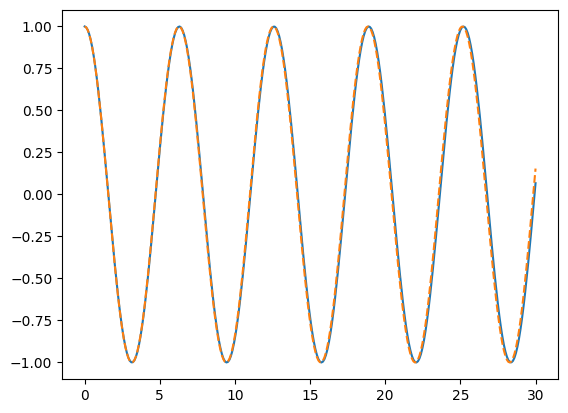

In [11]:
def acc(k, m, pos):
    return -k*pos/m

def trajectory(k, m, x0, v0, dt, N):

    pos = np.zeros(N)
    vel = np.zeros(N)
    pos[0] = x0
    vel[0] = v0

    for i in range(N-1):
        pos[i+1] = pos[i]+vel[i]*dt+0.5*acc(k, m, pos[i])*dt**2
        vel[i+1] = vel[i]+0.5*(acc(k,m,pos[i])+acc(k,m,pos[i+1]))*dt

    return pos, vel

k = 1
m = 1
x0 = 1
v0 = 0
dt = 0.1
N = int(30/0.1)
t = np.linspace(0,30,N)

pos, vel = trajectory(k, m, x0, v0, dt, N)

plt.plot(t, pos, t, np.cos(t),'--')

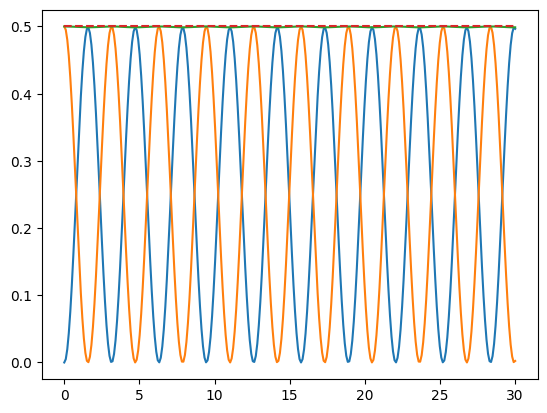

In [13]:
EK = 0.5*m*vel**2
EP = 0.5*k*pos**2
ET = EK+EP

plt.plot(t, EK, label='EK')
plt.plot(t, EP, label='EP')
plt.plot(t, ET, label='ET')
plt.plot(t, np.ones(len(t))*(EK[0]+EP[0]), '--')

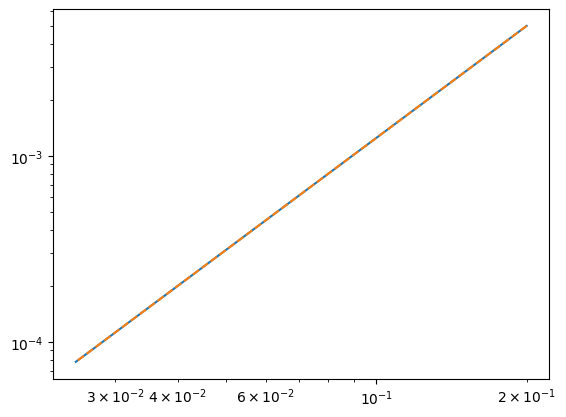

In [28]:
def error_analysis(k, m, x0, v0):
    
    dts = np.array([0.2, 0.1, 0.05, 0.025])
    errs = np.zeros(len(dts))
    
    for i in range(len(dts)):
        N = int(30/dts[i])
        pos, vel = trajectory(k, m, x0, v0, dts[i], N)
        
        ET = 0.5*(m*vel**2+k*pos**2)
        ET_exact = 0.5*(m*v0**2+k*x0**2)

        errs[i] = np.max(np.abs(ET-ET_exact))

    return dts, errs
    
dts, errs = error_analysis(k, m, x0, v0)

plt.plot(dts, errs, dts, errs[0]*dts**2/(dts[0]**2), '--')
plt.xscale('log')
plt.yscale('log')